# WIA3003: Academic Project II
## Improved QCNN: Trainable Encoding and Learned Readout

The initial QCNN scores below logistic regression. Logistic regression can weight each measurement. The initial QCNN cannot, because every measurement enters as a fixed rotation angle. This notebook tests one revised QCNN that combines four changes:

| Change | Initial QCNN | Improved QCNN |
| --- | --- | --- |
| Input scaling | Min-max to [0, pi] | Standardised (mean 0, std 1) |
| Encoding | RY(x) | RY(w·x + b), with trainable w and b per measurement |
| Readout | Fixed average of four Pauli-Z values | Trainable weighted sum through a sigmoid |
| Training length | 13 epochs | Up to 100 epochs, early stopping on validation loss |

The convolution and pooling gates are unchanged. The comparison uses the same five folds as notebook 14, so the initial QCNN and logistic regression results are read from there. Settings are fixed before running. Test folds are not used to choose anything. Claude assisted with writing and running this notebook.

## 1.0 Load Dataset and Saved Folds

In [1]:
import hashlib
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

folder = Path.cwd()
project_folder = folder.parent if folder.name == "notebooks" else folder
details = json.loads((project_folder / "results" / "qcnn_baseline" / "run_details.json").read_text(encoding="utf-8"))
reference_folder = project_folder / "results" / "ethnicity_evaluation"
reference_settings = json.loads((reference_folder / "cross_validation_settings.json").read_text(encoding="utf-8"))

data_path = Path.home() / "Downloads" / "Orbital, Nasal and Craniofacial Class Pattern.xls"
dataset_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
if dataset_hash != reference_settings["dataset_sha256"]:
    raise ValueError("Workbook changed since notebook 14. Verify the data first.")

df = pd.read_excel(data_path, sheet_name="Raw Data")
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
features = details["features"]
X = df[features].apply(pd.to_numeric, errors="raise").to_numpy(dtype=float)
y = df["Gender"].astype("string").str.strip().map(details["label_mapping"]).astype(int).to_numpy()
groups = pd.DataFrame(X).groupby(list(range(len(features))), sort=False).ngroup().to_numpy()

reference = pd.read_csv(reference_folder / "cross_validated_predictions.csv")
assert np.array_equal(reference["actual_label"], y)
fold_of = reference["fold"].to_numpy()
print("Records per fold:", np.bincount(fold_of).tolist())

Records per fold: [209, 209, 208, 208, 208]


## 2.0 Circuit

Parameter layout: 13 circuit angles as before, 8 input weights, 8 input offsets, 4 readout weights and 1 readout bias. Total 34.

Starting values make the new model begin close to the initial one. A standardised value of 0 maps to pi/2, and three standard deviations map to about 0 or pi. The readout starts as a scaled average.

In [2]:
n_qubits = 8
N_CIRCUIT, N_INPUT = 13, 8

def convolution_layer(parameters):
    for first in [0, 2, 4, 6, 1, 3, 5]:
        qml.Rot(*parameters[:3], wires=first)
        qml.Rot(*parameters[3:], wires=first + 1)
        qml.CNOT(wires=[first, first + 1])

@qml.qnode(qml.device("default.qubit", wires=n_qubits), interface="autograd", diff_method="backprop")
def qcnn_circuit(angles, weights):
    for wire in range(n_qubits):
        qml.RY(angles[..., wire], wires=wire)
    convolution_layer(weights[:6])
    convolution_layer(weights[6:12])
    for source in [0, 2, 4, 6]:
        qml.CRY(weights[12], wires=[source, source + 1])
    return [qml.expval(qml.PauliZ(wire)) for wire in [1, 3, 5, 7]]

def predict_probability(parameters, inputs):
    circuit = parameters[:N_CIRCUIT]
    input_weights = parameters[N_CIRCUIT:N_CIRCUIT + N_INPUT]
    input_offsets = parameters[N_CIRCUIT + N_INPUT:N_CIRCUIT + 2 * N_INPUT]
    readout_weights, readout_bias = parameters[-5:-1], parameters[-1]
    expectations = pnp.stack(qcnn_circuit(inputs * input_weights + input_offsets, circuit))
    score = pnp.tensordot(readout_weights, expectations, axes=1) + readout_bias
    return 1 / (1 + pnp.exp(-score))

def loss_function(parameters, inputs, labels):
    probabilities = pnp.clip(predict_probability(parameters, inputs), 1e-7, 1 - 1e-7)
    return -pnp.mean(labels * pnp.log(probabilities) + (1 - labels) * pnp.log(1 - probabilities))

def initialise(seed):
    rng = np.random.default_rng(seed)
    return pnp.array(np.concatenate([
        rng.uniform(-0.1, 0.1, N_CIRCUIT),
        np.full(N_INPUT, np.pi / 6), np.full(N_INPUT, np.pi / 2),
        np.full(4, -0.5), [0.0],
    ]), requires_grad=True)

print("Trainable parameters:", len(initialise(42)))

Trainable parameters: 34


### 2.1 Small Batch Checking

Check that batched and single-record predictions agree and that every parameter group receives a gradient. No test data are used.

In [3]:
check_scaler = StandardScaler().fit(X[fold_of != 0])
check_inputs = pnp.array(check_scaler.transform(X[fold_of != 0][:4]), requires_grad=False)
check_labels = pnp.array(y[fold_of != 0][:4], requires_grad=False)
check_weights = initialise(42)
batched = np.asarray(predict_probability(check_weights, check_inputs))
single = np.array([float(predict_probability(check_weights, row)) for row in check_inputs])
np.testing.assert_allclose(batched, single, rtol=1e-6, atol=1e-8)
gradient = np.asarray(qml.grad(lambda current: loss_function(current, check_inputs, check_labels))(check_weights))
assert np.isfinite(gradient).all()
print("Gradient norm by group:", {
    "circuit": round(float(np.linalg.norm(gradient[:13])), 4),
    "input weights": round(float(np.linalg.norm(gradient[13:21])), 4),
    "input offsets": round(float(np.linalg.norm(gradient[21:29])), 4),
    "readout": round(float(np.linalg.norm(gradient[29:])), 4),
})

Gradient norm by group: {'circuit': 0.737, 'input weights': 0.0576, 'input offsets': 0.2417, 'readout': 0.4656}


## 3.0 Training Settings

Within each training fold, hold out 20% as validation records, grouped and stratified. Train on the rest and keep the weights from the epoch with the lowest validation loss. Those weights predict the test fold. The model is not refitted on the full training fold, so each fold trains once.

In [4]:
SEED = 42
MAX_EPOCHS = 100
PATIENCE = 10
BATCH_SIZE = 32
LEARNING_RATE = 0.01

def train_fold(train_rows, test_rows):
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    fit_part, val_part = next(inner.split(X[train_rows], y[train_rows], groups[train_rows]))
    fit_rows, val_rows = train_rows[fit_part], train_rows[val_part]
    assert not set(groups[fit_rows]) & set(groups[val_rows])
    scaler = StandardScaler().fit(X[fit_rows])
    as_inputs = lambda rows: pnp.array(scaler.transform(X[rows]), requires_grad=False)
    fit_inputs, val_inputs = as_inputs(fit_rows), as_inputs(val_rows)
    fit_labels = pnp.array(y[fit_rows], requires_grad=False)
    val_labels = pnp.array(y[val_rows], requires_grad=False)

    weights = initialise(SEED)
    optimiser = qml.AdamOptimizer(stepsize=LEARNING_RATE)
    rng = np.random.default_rng(SEED)
    best_loss, best_weights, best_epoch, waiting, history = np.inf, None, 0, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        order = rng.permutation(len(fit_inputs))
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            weights = optimiser.step(lambda current: loss_function(current, fit_inputs[batch], fit_labels[batch]), weights)
        val_loss = float(loss_function(weights, val_inputs, val_labels))
        assert np.isfinite(val_loss)
        history.append({"Epoch": epoch, "Validation loss": val_loss})
        if val_loss < best_loss:
            best_loss, best_weights, best_epoch, waiting = val_loss, np.asarray(weights).copy(), epoch, 0
        else:
            waiting += 1
        if waiting >= PATIENCE:
            break
    probabilities = np.asarray(predict_probability(pnp.array(best_weights, requires_grad=False), as_inputs(test_rows)), dtype=float)
    return probabilities, best_weights, best_epoch, len(history), pd.DataFrame(history)

## 4.0 Run Cross-Validation

In [5]:
output_folder = project_folder / "results" / "qcnn_improved"
output_folder.mkdir(parents=True, exist_ok=True)
improved = np.empty(len(X))
fold_details, histories = [], []
for fold in range(5):
    started = time.perf_counter()
    train_rows, test_rows = np.flatnonzero(fold_of != fold), np.flatnonzero(fold_of == fold)
    improved[test_rows], weights, best_epoch, epochs_run, history = train_fold(train_rows, test_rows)
    np.save(output_folder / f"fold_{fold}_weights.npy", weights)
    histories.append(history.assign(Fold=fold))
    fold_details.append({"Fold": fold, "Best epoch": best_epoch, "Epochs run": epochs_run,
                         "Seconds": time.perf_counter() - started})
    print(f"Fold {fold + 1}: best epoch {best_epoch} of {epochs_run}, {fold_details[-1]['Seconds']:.0f} s", flush=True)
fold_details = pd.DataFrame(fold_details)
histories = pd.concat(histories, ignore_index=True)

Fold 1: best epoch 31 of 41, 196 s


Fold 2: best epoch 21 of 31, 155 s


Fold 3: best epoch 13 of 23, 114 s


Fold 4: best epoch 86 of 96, 350 s


Fold 5: best epoch 46 of 56, 221 s


## 5.0 Compare on the Same Folds

Threshold 0.5 for every model. Macro F1 treats female and male equally.

In [6]:
probability = {
    "Initial QCNN": reference["Initial QCNN probability_male"].to_numpy(),
    "Improved QCNN": improved,
    "Logistic regression": reference["Logistic regression probability_male"].to_numpy(),
}
rows = []
for name, values in probability.items():
    predicted = (values >= 0.5).astype(int)
    for fold in range(5):
        part = fold_of == fold
        rows.append({
            "Model": name, "Fold": fold,
            "Accuracy": accuracy_score(y[part], predicted[part]),
            "Macro F1": f1_score(y[part], predicted[part], average="macro"),
            "Female recall": recall_score(y[part], predicted[part], pos_label=0),
            "Male recall": recall_score(y[part], predicted[part], pos_label=1),
            "ROC AUC": roc_auc_score(y[part], values[part]),
        })
fold_scores = pd.DataFrame(rows)
summary = fold_scores.drop(columns="Fold").groupby("Model").agg(["mean", "std"]).reindex(list(probability))
summary.insert(0, "Parameters", [13, 34, 9])
display(summary.round(4))

paired = fold_scores.pivot(index="Fold", columns="Model", values="Macro F1")
paired["Improved minus initial"] = paired["Improved QCNN"] - paired["Initial QCNN"]
paired["Improved minus logistic"] = paired["Improved QCNN"] - paired["Logistic regression"]
display(paired.round(4))
display(fold_details.round(1))

Parameters Accuracy         Macro F1          \
                                   mean     std     mean     std   
Model                                                              
Initial QCNN                13   0.6890  0.0368   0.6767  0.0336   
Improved QCNN               34   0.7658  0.0247   0.7616  0.0224   
Logistic regression          9   0.7697  0.0324   0.7651  0.0327   

                    Female recall         Male recall         ROC AUC          
                             mean     std        mean     std    mean     std  
Model                                                                          
Initial QCNN               0.5671  0.0341      0.7836  0.0721  0.7462  0.0298  
Improved QCNN              0.7296  0.0307      0.7937  0.0606  0.8410  0.0206  
Logistic regression        0.7233  0.0458      0.8057  0.0400  0.8457  0.0233

Model,Improved QCNN,Initial QCNN,Logistic regression,Improved minus initial,Improved minus logistic
Fold,,,,,
0,0.7545,0.6434,0.7313,0.1112,0.0232
1,0.8002,0.7253,0.8024,0.0749,-0.0023
2,0.7552,0.6617,0.7763,0.0935,-0.0212
3,0.7415,0.6563,0.7303,0.0852,0.0111
4,0.7569,0.6967,0.7851,0.0602,-0.0282


,Fold,Best epoch,Epochs run,Seconds
0,0,31,41,195.6
1,1,21,31,154.6
2,2,13,23,113.9
3,3,86,96,349.8
4,4,46,56,220.6


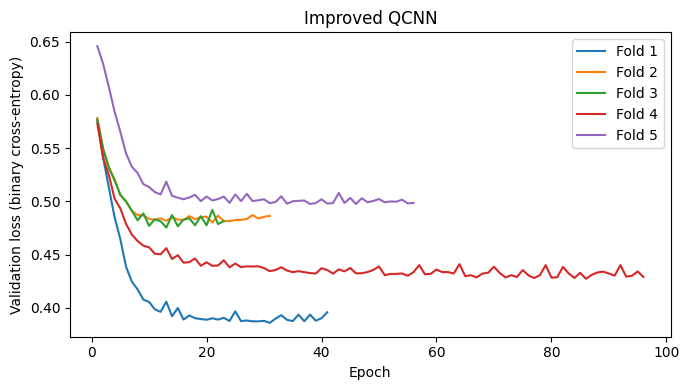

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for fold, history in histories.groupby("Fold"):
    ax.plot(history["Epoch"], history["Validation loss"], label=f"Fold {fold + 1}")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation loss (binary cross-entropy)")
ax.set_title("Improved QCNN")
ax.legend()
fig.tight_layout()
fig.savefig(output_folder / "validation_loss.png", dpi=200, bbox_inches="tight")
plt.show()

## 6.0 Learned Input Weights

Average absolute input weight per measurement across the five folds. A larger weight means the circuit rotates further per standard deviation of that measurement.

In [8]:
learned = np.stack([np.load(output_folder / f"fold_{fold}_weights.npy") for fold in range(5)])
input_weights = pd.DataFrame({
    "Measurement": features,
    "Mean |input weight|": np.abs(learned[:, 13:21]).mean(axis=0),
    "Std across folds": np.abs(learned[:, 13:21]).std(axis=0),
}).sort_values("Mean |input weight|", ascending=False)
display(input_weights.round(4))
print("Starting input weight:", round(np.pi / 6, 4))

,Measurement,Mean |input weight|,Std across folds
3,UMo-Lmo Orbital Height,0.8053,0.1383
2,LEc-LDc Left Orbital Width,0.7824,0.2992
7,Rh-Ns Nasal Height,0.7671,0.0530
6,RAI-LAI Nasal Width,0.6903,0.0445
0,Ec-Dc Orbital Width,0.4611,0.1596
1,REc-RDc Right Orbital Width,0.4443,0.2037
4,RUMo-RLMo Right Orbital Height,0.2468,0.1428
5,LUMo-LLMo Left Orbital Height,0.0779,0.0487


Starting input weight: 0.5236


## 7.0 Save Results

In [9]:
fold_scores.to_csv(output_folder / "fold_scores.csv", index=False)
summary.to_csv(output_folder / "summary.csv")
paired.to_csv(output_folder / "paired_macro_f1.csv")
fold_details.to_csv(output_folder / "fold_details.csv", index=False)
histories.to_csv(output_folder / "validation_history.csv", index=False)
input_weights.to_csv(output_folder / "input_weights.csv", index=False)
pd.DataFrame({"source_row_position": np.arange(len(X)), "fold": fold_of, "actual_label": y,
              "probability_male": improved}).to_csv(output_folder / "cross_validated_predictions.csv", index=False)
settings = {
    "dataset_sha256": dataset_hash, "features": features, "folds_from": "notebook 14",
    "architecture": "Standardised inputs, RY(w*x + b), two shared Rot-Rot-CNOT layers, CRY pooling, sigmoid of weighted Z on odd wires",
    "parameters": 34, "seed": SEED, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "threshold": 0.5,
    "inner_validation": "first fold of StratifiedGroupKFold(5) within each training fold",
    "pennylane_version": qml.__version__,
}
(output_folder / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print("Saved results to:", output_folder)

Saved results to: C:\Users\jwenn\Desktop\UM\FYP\FYP-Project\results\qcnn_improved
